In [106]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotx
import pandas as pd
from pathlib import Path

plt.style.use(matplotx.styles.ayu['light'])
DATA_DIR = Path("data")

In [107]:
Y = pd.read_csv(DATA_DIR / "small_movies_Y.csv", header=None)
R = pd.read_csv(DATA_DIR / "small_movies_R.csv", header=None)
movie_df = pd.read_csv(DATA_DIR / "small_movie_list.csv", index_col=0)
X = pd.read_csv(DATA_DIR / "small_movies_X.csv", header=None)
W = pd.read_csv(DATA_DIR / "small_movies_W.csv", header=None)
b = pd.read_csv(DATA_DIR / "small_movies_b.csv", header=None)

print("ratings_df:", Y.shape)
print("rated_df:", R.shape)
print("movie_df:", movie_df.shape)
print("movie_features_df:", X.shape)
print("user_features_df:", W.shape)
print("user_bias_df:", b.shape)

ratings_df: (4778, 443)
rated_df: (4778, 443)
movie_df: (4778, 3)
movie_features_df: (4778, 10)
user_features_df: (443, 10)
user_bias_df: (1, 443)


In [108]:
num_movies, num_features = X.shape
num_users, num_features = W.shape

print(num_movies, num_users, num_features)
X

4778 443 10


,0,1,2,3,4,5,6,7,8,9
0,-0.033287,1.166746,-0.506490,0.125096,1.534760,-0.210136,0.104176,-0.349303,0.753852,-0.208109
1,0.404058,2.266492,-0.742824,1.374039,1.145788,0.381959,-0.447495,-1.038103,-2.332266,-2.343191
2,0.023478,0.428102,-0.426381,0.107177,0.484193,-0.969298,-0.748563,-0.293784,0.439730,1.823422
3,0.511281,1.518797,1.602747,-2.296399,-0.570383,-0.480868,-0.662502,1.965215,0.495176,1.044845
4,-2.056514,0.458517,0.619371,-0.138456,0.011926,-0.282415,0.027502,-0.535465,0.661082,0.195084
...,...,...,...,...,...,...,...,...,...,...
4773,-0.473012,-1.069387,1.408808,-1.171842,1.222617,0.028973,0.230975,0.579943,-0.828117,-0.132676
4774,0.340389,3.040022,0.208837,-1.056347,-0.561943,0.583073,-1.171645,1.152431,0.363426,0.178877
4775,-0.438083,0.711810,-0.298449,-0.459011,1.824691,-0.036751,0.054586,0.148413,-0.439178,-0.062395
4776,1.137175,0.865196,1.066511,0.878567,0.579996,1.311802,-0.290936,0.619440,0.377445,-3.411507


In [109]:
movie112 = X.iloc[112]
movie112 = movie112[:2].to_numpy()
print("Movie features: ", movie112)

user1 = W.iloc[0]
user1 = user1[:2].to_numpy()
print("User features: ", user1)

bias = b[0][0]
print(bias)

print("Predicted Rating: ", np.dot(movie112, user1) + bias)
print("Actual rating: ", Y[112][0])

Movie features:  [0.37545577 0.9578223 ]
User features:  [0.47935075 0.4766997 ]
0.23609531
Predicted Rating:  0.8726639180046376
Actual rating:  5.0


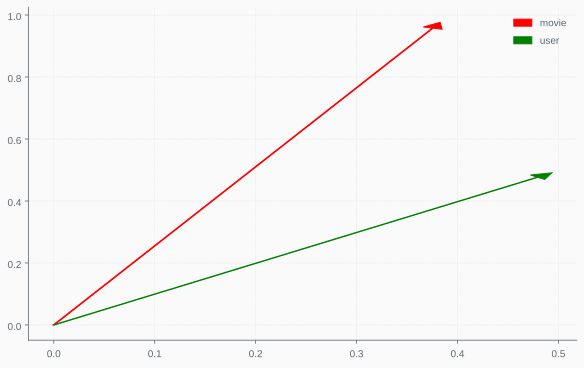

In [110]:
fig, ax = plt.subplots(figsize = (8, 5))
ax.arrow(0, 0, *movie112, head_width = .02, head_length = 0.02, ec = 'r', fc = 'r', label = "movie")
ax.arrow(0, 0, *user1, head_width = .02, head_length = 0.02, ec = 'g', fc = 'g', label = "user")
plt.grid(True)
plt.legend()